# Solar Filament Segmentation — Full Pipeline

This notebook reproduces the submitted predictions end to end, from test
images alone. It is the notebook the competition asks for: *"a Jupyter
notebook illustrating the full pipeline. The committee must be able to
reproduce predictions without any additional files."*

## What it does

1. Check the environment and locate the data
2. Fetch the trained weights (~994 MB, from a GitHub release)
3. Preprocess: estimate the solar disk, flatten the radial gradient
4. Run the five-fold ConvNeXt-Small ensemble, averaged in probability space
5. Generate candidates and re-score them with a gradient-boosted model
6. Write the submission CSV in COCO RLE format

## Why two stages

The expensive part is five model forwards per image. The cheap part is
candidate scoring. They are separated so the scorer can be inspected and
adjusted without repeating inference.

## Requirements

`pip install -r requirements.txt`, and the competition data in
`MAGFiLO_1.0_Kaggle_2026/`. Inference needs no network access once the weights
are fetched: the checkpoint supplies every weight, so the pretrained backbone
is never downloaded.

## 1. Environment

Resolve the repository root from the notebook's own location so the notebook
works regardless of where Jupyter was launched. Fail early and clearly if the
competition data is missing, rather than partway through inference.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

DATA = ROOT / "MAGFiLO_1.0_Kaggle_2026"
TEST_DIR = DATA / "test" / "test_images"
WEIGHTS = ROOT / "weights"
OUT = ROOT / "submission.csv"

print(f"python  {sys.version.split()[0]}")
print(f"root    {ROOT}")
print(f"data    {DATA}  exists={DATA.exists()}")
print(f"test    {TEST_DIR}  exists={TEST_DIR.exists()}")

if not TEST_DIR.exists():
    raise SystemExit(
        f"competition data not found at {DATA}.\n"
        "Download it from https://www.kaggle.com/competitions/"
        "filament-segmentation-2026 and extract it to the repo root."
    )

python  3.12.3
root    /media/yasir/HDD/drive/repos/competitions/solar
data    /media/yasir/HDD/drive/repos/competitions/solar/MAGFiLO_1.0_Kaggle_2026  exists=True
test    /media/yasir/HDD/drive/repos/competitions/solar/MAGFiLO_1.0_Kaggle_2026/test/test_images  exists=True


In [2]:
import csv
import json

import cv2
import joblib
import matplotlib.pyplot as plt
import numpy as np
import torch
from tqdm.auto import tqdm

from solar.data import normalise_image, parse_preprocess, preprocess_image
from solar.instances import candidate_features, generate_candidates
from solar.models import build_model
from solar.postprocess import labelmap_to_rle
from solar.predict import predict_prob

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"torch   {torch.__version__}")
print(f"device  {device}")
if device == "cpu":
    print("  (CPU works but is slow: ~4 s per fold per image against 0.15 s on GPU)")

/media/yasir/HDD/drive/repos/competitions/solar/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


torch   2.14.1+cu130
device  cuda


## 2. Fetch the weights

The five fold checkpoints are 208 MB each, which is over GitHub's 100 MB file
limit, so they are published as release assets rather than committed. The
script is idempotent: files already present with the right size are skipped.

In [3]:
import subprocess

if not (WEIGHTS / "seg_v2_fold0" / "best.pt").exists():
    print("weights missing, fetching (~994 MB)...")
    subprocess.run(
        [sys.executable, str(ROOT / "scripts" / "fetch_weights.py"),
         "--out", str(WEIGHTS)],
        check=True,
    )
else:
    print("weights already present")

for f in range(5):
    p = WEIGHTS / f"seg_v2_fold{f}" / "best.pt"
    print(f"  fold{f}: {p.stat().st_size / 1e6:.0f} MB" if p.exists()
          else f"  fold{f}: MISSING")

weights already present
  fold0: 208 MB
  fold1: 208 MB
  fold2: 208 MB
  fold3: 208 MB
  fold4: 208 MB


## 3. Preprocessing

Ground-based H-alpha images have a strong radial intensity gradient from limb
darkening and atmospheric path length. We estimate the solar disk geometry
from the image itself and divide out a background profile fitted on concentric
annuli.

This **must** run at full resolution: the profile spans the whole disk, so a
512 px crop cannot supply it. That is why preprocessing happens before any
patching.

The figure below shows what flattening does — the filament is a dark, thin
structure that becomes visible once the gradient is removed.

In [4]:
test_files = sorted(
    p for p in TEST_DIR.iterdir()
    if p.suffix.lower() in (".jpeg", ".jpg", ".png")
)
print(f"{len(test_files)} test images")

# Read the config from a checkpoint: the preprocessing parameters are part of
# the trained model, not a free choice at inference time.
ckpt0 = torch.load(WEIGHTS / "seg_v2_fold0" / "best.pt",
                   map_location="cpu", weights_only=False)
CFG = ckpt0["cfg"]
MEAN, STD = CFG["data"]["mean"], CFG["data"]["std"]
PP_STEPS = parse_preprocess(CFG["data"].get("preprocess"))
MASK_OFFDISK = CFG["data"].get("mask_offdisk", False)
OFFDISK_VALUE = CFG["data"].get("offdisk_value", -3.0)

# Test-time augmentation: each fold's map is the mean of four flip variants
# (identity, horizontal, vertical, both). Measured on this pipeline, TTA is worth
# +0.0063 PQ at the segmentation stage and +0.0094 after re-scoring (paired
# +0.0073, CI [+0.0033, +0.0113]).
#
# TTA=True reproduces `submissions/seg_v2_phase2_tta.csv` (1069 filaments).
# TTA=False reproduces `submissions/seg_v2_phase2.csv` (1093 filaments), which is
# what the first submission used because `predict_test_phase2.py` declares
# `--tta` as `store_true` and the flag was not passed. Both scored 0.38 on the
# public leaderboard; TTA=True is the protocol the report describes.

TTA = True

print(f"mask off-disk    : {MASK_OFFDISK}")

print(f"normalisation    : mean {MEAN:.4f}  std {STD:.4f}")
print(f"preprocess steps : {sorted(PP_STEPS)}")

180 test images
mask off-disk    : False
normalisation    : mean 0.4254  std 0.0809
preprocess steps : ['flatten']


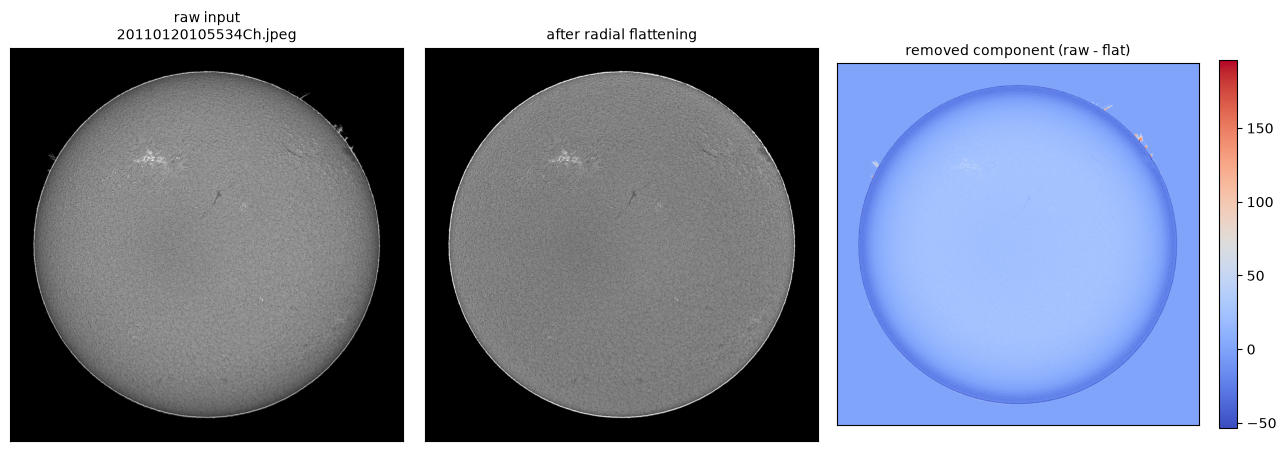

raw range  0..255
flat range 0.0..232.7


In [5]:
sample = test_files[0]
raw = cv2.imread(str(sample), cv2.IMREAD_GRAYSCALE)
flat, disk = preprocess_image(raw, PP_STEPS)

fig, axes = plt.subplots(1, 3, figsize=(13, 4.4))
axes[0].imshow(raw, cmap="gray")
axes[0].set_title(f"raw input\n{sample.name}", fontsize=10)

axes[1].imshow(flat, cmap="gray")
axes[1].set_title("after radial flattening", fontsize=10)

# The difference is the gradient that flattening removes.
diff = raw.astype(np.float32) - flat
im = axes[2].imshow(diff, cmap="coolwarm")
axes[2].set_title("removed component (raw - flat)", fontsize=10)
plt.colorbar(im, ax=axes[2], fraction=0.046)

for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

print(f"raw range  {raw.min()}..{raw.max()}")
print(f"flat range {flat.min():.1f}..{flat.max():.1f}")

## 4. The five-fold ensemble

Each fold is a ConvNeXt-Small UNet trained on four of the five week-based
folds. At inference all five predict every test image and the probability maps
are **averaged before thresholding**.

Averaging in probability space rather than voting on binary masks matters: a
pixel that three folds are confident about survives even if two are not, and
the averaged map stays calibrated — which the candidate scorer depends on.

`pretrained=False` is deliberate. The checkpoint supplies every weight, so
there is no reason to download ImageNet initialisations, and inference then
works with no network access.

In [6]:
models = []
for f in range(5):
    ck = torch.load(WEIGHTS / f"seg_v2_fold{f}" / "best.pt",
                    map_location="cpu", weights_only=False)
    cfg_f = dict(ck["cfg"])
    # No network: the checkpoint has every weight already.
    cfg_f["model"] = {**cfg_f["model"], "pretrained": False}
    m = build_model(cfg_f).to(device)
    m.load_state_dict(ck["model"], strict=True)
    m.eval()
    models.append(m)
    print(f"fold {f}: epoch {ck.get('epoch')}  val PQ {ck.get('pq', 0):.4f}")

n_params = sum(p.numel() for p in models[0].parameters())
print(f"\n{n_params / 1e6:.1f}M parameters per fold, {len(models)} folds loaded")

fold 0: epoch 110  val PQ 0.4177


fold 1: epoch 109  val PQ 0.4166


fold 2: epoch 116  val PQ 0.4163


fold 3: epoch 106  val PQ 0.4330


fold 4: epoch 56  val PQ 0.3911

52.0M parameters per fold, 5 folds loaded


### Ensemble on one image

Before running all 180 images, look at what the ensemble actually does on one.
The individual folds disagree at the boundaries; the average is smoother than
any single member, which is the variance reduction the ensemble is for.

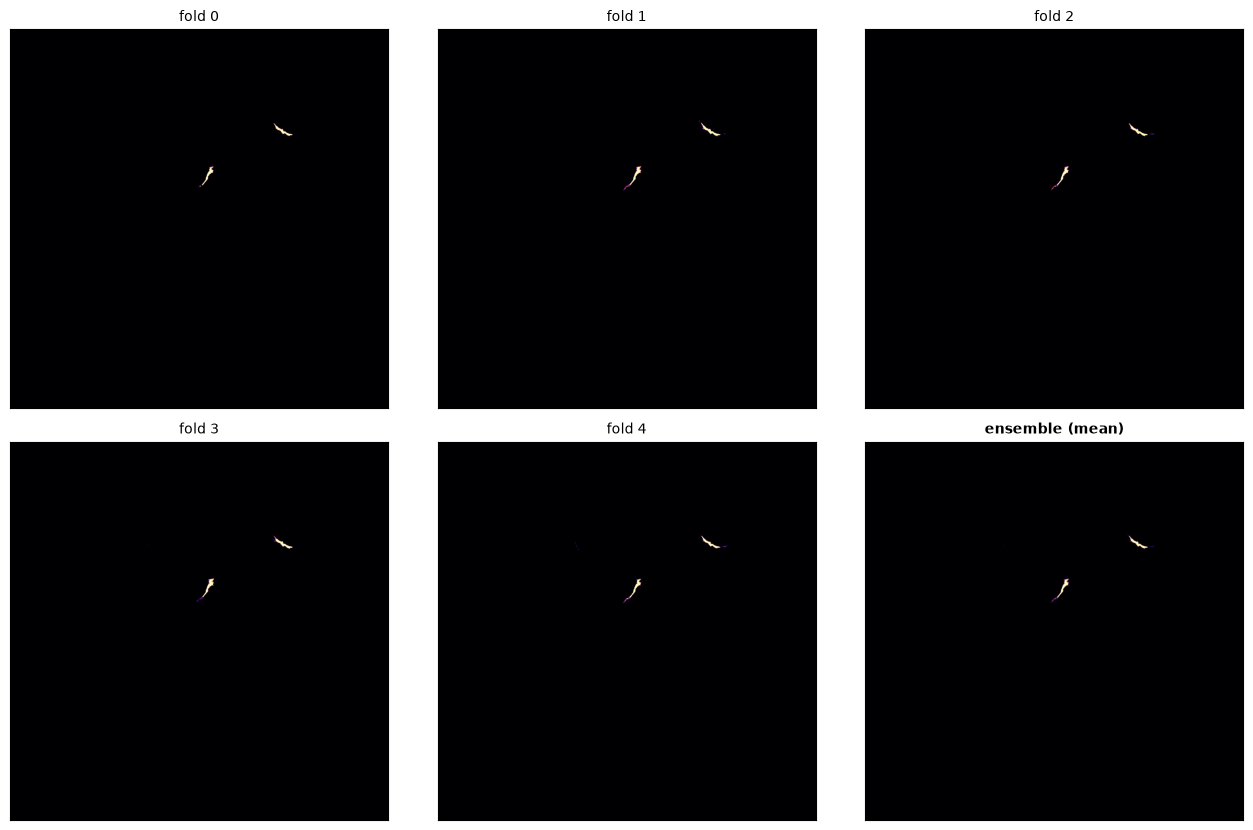

ensemble prob: min 0.000  max 1.000  mean 0.0007
pixels above 0.5: 2,717 (0.065% of the frame)


In [7]:
raw = cv2.imread(str(sample), cv2.IMREAD_GRAYSCALE)
flat, disk = preprocess_image(raw, PP_STEPS)
x = normalise_image(flat, MEAN, STD, disk=disk,
                    mask_offdisk=MASK_OFFDISK, offdisk_value=OFFDISK_VALUE)
tensor = torch.from_numpy(x).unsqueeze(0).to(device)

fold_probs = []
with torch.no_grad():
    for m in models:
        fold_probs.append(predict_prob(m, tensor, tta=TTA))
ens = np.mean(fold_probs, axis=0)

fig, axes = plt.subplots(2, 3, figsize=(13, 8.4))
for i, ax in enumerate(axes.flat[:5]):
    ax.imshow(fold_probs[i], cmap="magma", vmin=0, vmax=1)
    ax.set_title(f"fold {i}", fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
axes.flat[5].imshow(ens, cmap="magma", vmin=0, vmax=1)
axes.flat[5].set_title("ensemble (mean)", fontsize=10, fontweight="bold")
axes.flat[5].set_xticks([]); axes.flat[5].set_yticks([])
plt.tight_layout()
plt.show()

print(f"ensemble prob: min {ens.min():.3f}  max {ens.max():.3f}  "
      f"mean {ens.mean():.4f}")
print(f"pixels above 0.5: {(ens > 0.5).sum():,} "
      f"({100 * (ens > 0.5).mean():.3f}% of the frame)")

## 5. Candidates and re-scoring

Thresholding at a low value and labelling connected components deliberately
**over-produces** candidates. A candidate rejected later costs nothing; a
filament that never becomes a candidate is unrecoverable.

Each candidate is described by 17 scalars — area, elongation, length,
orientation, probability statistics, contrast against a surrounding ring,
bounding-box shape, border contact, centroid — and a gradient-boosted model
predicts the probability that it is a true positive. Candidates below
`tau = 0.35` are discarded.

This stage is where the gain comes from, and it is a **ranking** problem: the
candidate set already contains the right answer.

In [8]:
bundle = joblib.load(WEIGHTS / "gbdt_qhat.joblib")
scorer, FEATURES = bundle["model"], bundle["features"]
print(f"scorer: {len(FEATURES)} features")
print(f"  {FEATURES}")

CAND_THR = 0.30      # low on purpose: over-produce, then filter
CAND_MIN_AREA = 128
TAU = 0.35           # q-hat threshold for keeping a candidate


cand = generate_candidates(ens, threshold=CAND_THR, min_area=CAND_MIN_AREA)
n_cand = int(cand.max())
print(f"\ncandidates at thr {CAND_THR} / area {CAND_MIN_AREA}: {n_cand}")

feats = [candidate_features(ens, cand, cid) for cid in range(1, n_cand + 1)]
X = np.asarray([[f[k] for k in FEATURES] for f in feats], np.float32)
q_hat = scorer.predict(X)

keep = q_hat > TAU
print(f"kept {keep.sum()} of {n_cand} at tau {TAU}")
print(f"q-hat range {q_hat.min():.3f}..{q_hat.max():.3f}")

scorer: 17 features
  ['area', 'log_area', 'elongation', 'length', 'angle', 'mean_prob', 'max_prob', 'p90_prob', 'frac_above_05', 'contrast', 'ring_mean', 'bbox_h', 'bbox_w', 'fill_ratio', 'touch_border', 'cy', 'cx']

candidates at thr 0.3 / area 128: 2
kept 2 of 2 at tau 0.35
q-hat range 0.665..0.754


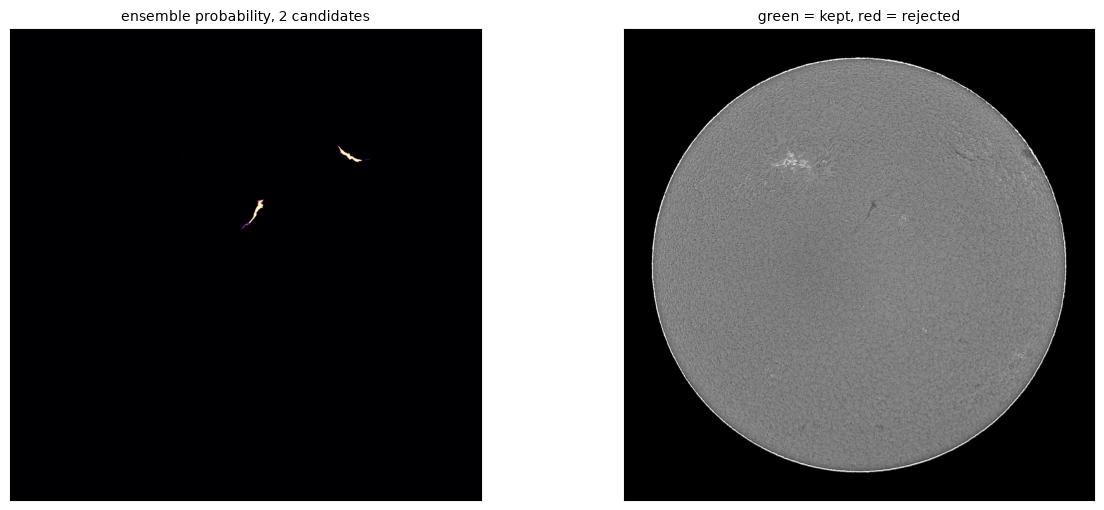

In [9]:
# Visualise which candidates survived. This is the whole method in one image:
# the network proposes, the scorer decides.
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))

axes[0].imshow(ens, cmap="magma", vmin=0, vmax=1)
axes[0].set_title(f"ensemble probability, {n_cand} candidates", fontsize=10)

axes[1].imshow(flat, cmap="gray")
for cid in range(1, n_cand + 1):
    mask = cand == cid
    edge = np.zeros_like(mask)
    edge[:-1, :] |= mask[:-1, :] != mask[1:, :]
    edge[:, :-1] |= mask[:, :-1] != mask[:, 1:]
    edge &= mask
    colour = "#2ca02c" if keep[cid - 1] else "#d62728"
    axes[1].imshow(np.where(edge, 1.0, np.nan), cmap="autumn", vmin=0, vmax=1,
                   alpha=0.0)  # placeholder to keep the extent
    ys, xs = np.nonzero(edge)
    axes[1].scatter(xs, ys, s=0.35, c=colour, marker="s", linewidths=0)
axes[1].set_title("green = kept, red = rejected", fontsize=10)

for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

## 6. Run the full pipeline

Now the same steps over all 180 test images. The probability maps are cached to
disk so the scoring stage can be re-run without repeating inference.

On an RTX 3090 this takes roughly 6 minutes; on CPU, considerably longer.

In [10]:
PROBS = ROOT / "test_probs"
PROBS.mkdir(exist_ok=True)

for path in tqdm(test_files, desc="ensemble"):
    out = PROBS / f"{path.stem}.npy"
    if out.exists():
        continue
    img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise FileNotFoundError(path)
    img, disk = preprocess_image(img, PP_STEPS)
    x = normalise_image(img, MEAN, STD, disk=disk,
                        mask_offdisk=MASK_OFFDISK, offdisk_value=OFFDISK_VALUE)
    tensor = torch.from_numpy(x).unsqueeze(0).to(device)

    acc = None
    with torch.no_grad():
        for m in models:
            p = predict_prob(m, tensor, tta=TTA)
            acc = p if acc is None else acc + p
    np.save(out, (acc / len(models)).astype(np.float16))

print(f"{len(list(PROBS.glob('*.npy')))} probability maps cached -> {PROBS}")

ensemble:   0%|          | 0/180 [00:00<?, ?it/s]

ensemble:   1%|          | 1/180 [00:05<16:13,  5.44s/it]

ensemble:   1%|          | 2/180 [00:11<16:55,  5.71s/it]

ensemble:   2%|▏         | 3/180 [00:16<16:36,  5.63s/it]

ensemble:   2%|▏         | 4/180 [00:22<16:51,  5.75s/it]

ensemble:   3%|▎         | 5/180 [00:29<17:24,  5.97s/it]

... (173 outputs left out)

ensemble:  99%|█████████▉| 179/180 [16:39<00:05,  5.43s/it]

ensemble: 100%|██████████| 180/180 [16:44<00:00,  5.43s/it]

ensemble: 100%|██████████| 180/180 [16:44<00:00,  5.58s/it]

180 probability maps cached -> /media/yasir/HDD/drive/repos/competitions/solar/test_probs


## 7. Write the submission

Each kept candidate becomes one instance, encoded as a COCO RLE *counts*
string. The image size is fixed at 2048x2048, so only the counts are needed.

`filament_id` is `{image_stem}_{instance_number}`.

In [11]:
rows = 0
counts_per_image = []
empty = []
n_cand_total = n_kept_total = 0

with open(OUT, "w", newline="") as fh:
    writer = csv.writer(fh)
    writer.writerow(["filament_id", "segmentation_rle"])

    for path in tqdm(sorted(PROBS.glob("*.npy")), desc="score"):
        prob = np.load(path).astype(np.float32)
        cand = generate_candidates(prob, threshold=CAND_THR,
                                   min_area=CAND_MIN_AREA)
        n = int(cand.max())
        n_cand_total += n

        if n == 0:
            counts_per_image.append(0)
            empty.append(path.stem)
            continue

        feats = [candidate_features(prob, cand, cid)
                 for cid in range(1, n + 1)]
        X = np.asarray([[f[k] for k in FEATURES] for f in feats], np.float32)
        q = scorer.predict(X)
        keep = np.concatenate([[False], q > TAU])
        n_kept_total += int(keep.sum())

        # Relabel kept candidates 1..k so labelmap_to_rle emits only those.
        lut = np.zeros(n + 1, np.int32)
        nxt = 1
        for cid in range(1, n + 1):
            if keep[cid]:
                lut[cid] = nxt
                nxt += 1
        labelmap = lut[cand]

        rles = labelmap_to_rle(labelmap)
        for inst, counts in rles.items():
            writer.writerow([f"{path.stem}_{inst}", counts])
            rows += 1
        counts_per_image.append(len(rles))
        if not rles:
            empty.append(path.stem)

print(f"\nwrote {rows} filaments -> {OUT}")
print(f"candidates {n_cand_total} -> kept {n_kept_total} "
      f"({n_kept_total / max(1, n_cand_total):.1%})")

score:   0%|          | 0/180 [00:00<?, ?it/s]

score:   1%|          | 1/180 [00:00<00:50,  3.56it/s]

score:   1%|          | 2/180 [00:00<00:49,  3.58it/s]

score:   2%|▏         | 3/180 [00:00<00:52,  3.36it/s]

score:   2%|▏         | 4/180 [00:01<01:14,  2.35it/s]

score:   3%|▎         | 5/180 [00:02<01:20,  2.18it/s]

... (169 outputs left out)

score:  99%|█████████▉| 179/180 [01:56<00:00,  2.45it/s]

score: 100%|██████████| 180/180 [01:56<00:00,  3.00it/s]

score: 100%|██████████| 180/180 [01:56<00:00,  1.55it/s]


wrote 1069 filaments -> /media/yasir/HDD/drive/repos/competitions/solar/submission.csv
candidates 1612 -> kept 1069 (66.3%)


## 8. Verify the submission

Check the output against the numbers reported in the paper. If these do not
match, the pipeline has drifted from the one that produced the submitted
predictions — which is exactly the failure this notebook exists to rule out.

In [12]:
counts = np.asarray(counts_per_image)
print(f"images            {len(counts)}")
print(f"filaments         {rows}")
print(f"per image         mean {counts.mean():.2f}  min {counts.min()}  "
      f"max {counts.max()}")
print(f"empty images      {len(empty)}")
if empty:
    print(f"  {empty[:8]}")

# The TTA submission produced 1069 filaments over 180 images with 3 empty.
# (The no-TTA submission produced 1093; both scored 0.38 publicly.)
EXPECTED = {"images": 180, "filaments": 1069, "empty": 3}
print("\nagainst the submitted run:")
for k, v in EXPECTED.items():
    got = {"images": len(counts), "filaments": rows, "empty": len(empty)}[k]
    print(f"  {k:10s} expected {v:5d}  got {got:5d}  "
          f"{'OK' if got == v else 'DIFFERS'}")

images            180
filaments         1069
per image         mean 5.94  min 0  max 16
empty images      3
  ['20170708164010Mh', '20200310113230Ch', '20211214174010Mh']

against the submitted run:
  images     expected   180  got   180  OK
  filaments  expected  1069  got  1069  OK
  empty      expected     3  got     3  OK


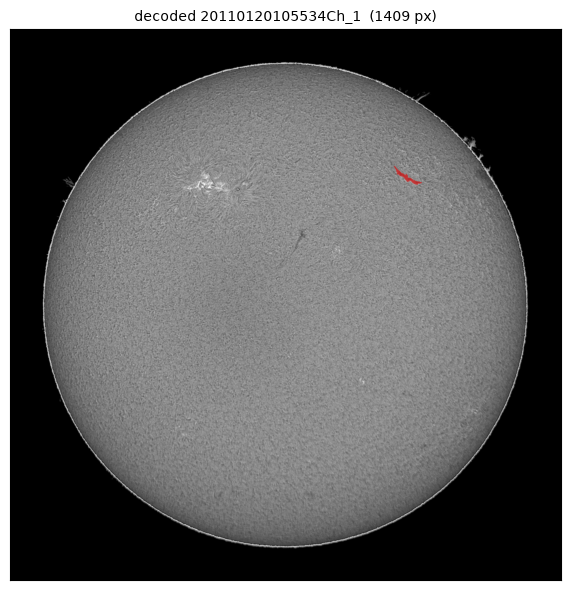

decoded mask: (2048, 2048), 1409 pixels
submission:   /media/yasir/HDD/drive/repos/competitions/solar/submission.csv  (0.30 MB)


In [13]:
# Decode one RLE back to a mask and overlay it, as a final sanity check that
# the encoding round-trips.
from pycocotools import mask as mask_utils

with open(OUT) as fh:
    reader = csv.DictReader(fh)
    first = next(reader)

stem = first["filament_id"].rsplit("_", 1)[0]
rle = {"size": [2048, 2048], "counts": first["segmentation_rle"].encode()}
mask = mask_utils.decode(rle)

img = cv2.imread(str(TEST_DIR / f"{stem}.jpeg"), cv2.IMREAD_GRAYSCALE)
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(img, cmap="gray")
ax.imshow(np.where(mask, 1.0, np.nan), cmap="autumn", alpha=0.55)
ax.set_title(f"decoded {first['filament_id']}  ({int(mask.sum())} px)",
             fontsize=10)
ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

print(f"decoded mask: {mask.shape}, {int(mask.sum())} pixels")
print(f"submission:   {OUT}  ({OUT.stat().st_size / 1e6:.2f} MB)")

## Notes on what this notebook does not do

**It does not train.** Training is in `src/solar/train.py` and takes ~6 hours
per fold on an RTX 3090. The checkpoints here are the trained artefacts.

**It does not evaluate.** There is no ground truth for the test set. Local
evaluation uses pooled out-of-fold predictions on the training set; see
`v2/scripts/score_oof.py` and `v2/results/summary.json`.

**It uses the GBDT scorer alone**, not the rank-average blend that scored
marginally higher on out-of-fold data (0.4406 against 0.4386). The blend's
+0.0020 is inside the paired confidence interval, and its threshold is a
*quantile* — which depends on the candidate distribution, and that distribution
differs on test (11.7% of test files are from 2021-22 against 5.7% of
training). An absolute threshold on a calibrated score transfers; a rank
threshold does not.

## Where the remaining error is

Scoring every candidate with its true label gives an oracle ceiling of PQ
0.5028, i.e. +0.0808 above the segmentation baseline. The learned scorer
captures +0.0186 of that (23%), leaving +0.0622 unclaimed. The error is
dominated by *missed* instances rather than imprecise boundaries: 16.7% of
ground-truth filaments score below 0.10 Dice. See the technical report for the
full analysis.